# Wind-Tunnel Acoustic Source-Power Imaging

Recover a planar aeroacoustic source-power map from a full measured 56-microphone wind-tunnel recording despite finite-aperture smearing and incoherent sensor contamination.

This maintainer notebook actively reconstructs the complete bound observations with local numerical modules. It distinguishes the independently reproduced original method from fresh cleaned results. There is no cache-preview path. The paper describes the selected model; the exact bound dataset and modern port have separate provenance.

## Observation and inverse problem

For frequency f, let C=E[ppᴴ] be the cross-spectral microphone matrix in Pa², with p the complex microphone spectrum and H denoting conjugate transpose. A monopole at position g has transfer h[m,g]=(r0[g]/r[m,g]) exp[-i k(r[m,g]-r0[g])], where r is source-to-microphone distance (m), r0 is source-to-array-origin distance (m), and k=2πf/c (rad/m) for sound speed c. Assume mutually incoherent source powers q[g]>=0, giving C approximately sum_g q[g] h[:,g] h[:,g]ᴴ plus noise.

The true-level steering vector v[g]=h[:,g]/sum_m abs(h[m,g])² yields a dirty power image b[g]=v[g]ᴴ C v[g], with sensor diagonal removed and correction M/(M-1) for M valid channels. Its point-spread matrix is A[g,j]=abs(v[g]ᴴh[:,j])². Recover q from b approximately A q and sum the per-bin q over the declared third-octave band. Finite aperture makes nearby source columns similar and the inverse nonunique.

Use the complete 25600-sample measured record and all 56 stored channels, excluding only the two documented invalid channels. The source plane is fixed at z=-0.68 m. This free-field incoherent-power model does not reconstruct source phase, account for flow refraction or claim calibrated physical source truth.

## Implemented mathematics and numerical conventions

Calibrate every native channel by its exact stored Pa/unit factor, then remove channels 1 and 7. Use all 25600 samples. Welch CSM uses 128-sample np.hanning windows (symmetric Hann), 64-sample hop, 399 complete blocks, no detrending and no zero padding. For spectra X_b=FFT(window*p_b), C=sum_b X_b X_bᴴ *2/(128*sum(window²)*399). This is one-sided power per bin, including the source convention of doubling DC/Nyquist, although neither is used by the selected band. Native FFT bin spacing is 400 Hz. Include 3600,4000,4400 Hz by the exact half-open third-octave bound.

Grid x=linspace(-0.6,0,13), y=linspace(-0.3,0.3,13), z=-0.68 m, flattened with y varying fastest, then restored to shape (13,13). Euclidean distances use supplied Cartesian sensor coordinates. True-level transfer, steering and incoherent PSF follow the README equations. Upstream fast kernels cast phase arguments to float32 while retaining complex128 accumulation; local code evaluates trigonometry at those rounded phases, correctly rounds results to float32 and then accumulates in float64. This avoids NumPy SIMD sine/cosine approximation differences in nearly cancelling dirty-map pixels and preserves upstream conventions rather than changing the stage tolerance.

To obtain b, remove CSM diagonal, evaluate the Hermitian quadratic form and multiply by M/(M-1), M=54, then clamp physically negative dirty-map pixels to zero. A uses the full coherent PSF (no diagonal removal) with A_gg=1. Initialize x=b. Perform exactly 100 projected Gauss–Seidel sweeps in flattened grid order: x_g=max(0,b_g-sum_(j!=g) A_gj x_j), using already updated earlier entries, relaxation factor one and no extra division because diagonal equals one. Sum solved powers across all included bins. There is no convergence-based early termination or generic optimizer substitution.

The notebook contrasts delay-and-sum and DAMAS; recomputes 1,10,100 iterations, c=336.04,346.04,356.04 m/s and durations 0.125,0.25,0.5 s. These address deconvolution, calibration and finite-time sensitivity. The broad upstream software demonstration includes unrelated estimators; it is not a multi-method benchmark claim here, and those estimators are deliberately outside this selected DAMAS task. Full measured input is preserved instead of the shorter 16000-sample illustrative upstream example. Zenodo's description says one second; the distributed file actually holds 25600 samples at 51200 Hz, so this task uses the actual 0.5-second record and records that discrepancy.

In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,time,json,subprocess,hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),Path.cwd().parent] if (p/'src').is_dir())
os.chdir(ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.main import run
from src.visualization import make_figures,relative_error
data=load_data()
display(Markdown('| Observation | Internal shape | Dtype |\n| --- | --- | --- |\n'+'\n'.join(f'| {k} | {v.shape} | {v.dtype} |' for k,v in data.items())))

| Observation | Internal shape | Dtype |
| --- | --- | --- |
| microphone_signal | (25600, 56) | float32 |
| microphone_position | (56, 3) | float64 |
| calibration_factor | (56,) | float64 |

## Fresh full reconstruction

The standard local path below computes every required output quantity from the bound public measurements and writes the declared submission. Runtime includes the complete reconstruction. Evaluation is a separate subprocess using the standalone Judge.

In [2]:
start=time.perf_counter()
fresh=run()
solver_runtime_s=time.perf_counter()-start
judge_process=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True,encoding='utf8',env=dict(os.environ,PYTHONIOENCODING='utf-8'))
assert judge_process.returncode==0,judge_process.stderr
judge_report=json.loads(Path('output/judge_report.json').read_text(encoding='utf8'))
assert judge_report['status']=='pass'
with np.load('evaluation/baseline_reference.npz',allow_pickle=False) as f:reference={k:f[k].copy() for k in f.files}
agreement={key:relative_error(fresh[key],reference[key]) for key in fresh}
print(json.dumps({'identity':'fresh cleaned full reconstruction','solver_runtime_s':solver_runtime_s,'upstream_relative_errors':agreement,'standalone_judge':judge_report},indent=2,allow_nan=False))

{
  "identity": "fresh cleaned full reconstruction",
  "solver_runtime_s": 0.3646299000829458,
  "upstream_relative_errors": {
    "reconstruction": 9.037926868168362e-10
  },
  "standalone_judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "reconstruction_relative_error": 9.037926868168362e-10
    },
    "thresholds": {
      "reconstruction_relative_error": {
        "comparison": "<=",
        "boundary": 1e-05
      }
    },
    "errors": []
  }
}


## Scientific comparisons and recomputed experiments

The reconstruction figure includes measured signal consistency and independently reproduced upstream comparison. The robustness figure recomputes its model/regularization and acquisition/calibration changes. Original arrays are comparison inputs only; every curve labeled fresh is computed here. Exact numerical trace arrays are returned for the separately archived figure exports.

In [3]:
experiment_start=time.perf_counter()
figures,plot_trace,experiment_metrics=make_figures(data,fresh,reference)
plt.close('all')
experiment_runtime_s=time.perf_counter()-experiment_start
measurement={'identity':'fresh cleaned notebook reconstruction and actively recomputed comparisons','raw_data_sha256':hashlib.sha256(Path('data/raw_data.npz').read_bytes()).hexdigest(),'solver_runtime_s':solver_runtime_s,'experiments_runtime_s':experiment_runtime_s,'upstream_relative_errors':agreement,'scientific_measurements':experiment_metrics,'judge':judge_report,'historical_paper_numbers_used':False}
Path('notebooks/reference_outputs/fresh_measurements.json').write_text(json.dumps(measurement,indent=2,allow_nan=False)+'\n',encoding='utf8')
print(json.dumps(experiment_metrics,indent=2,allow_nan=False))

{
  "upstream_relative_error": 9.037926868168362e-10,
  "das_sum_Pa2": 0.000498664513456107,
  "damas_sum_Pa2": 0.00016376417491529414,
  "iteration_total_peak_Pa2": [
    [
      1,
      0.00010511242634044538,
      2.882280636053904e-05
    ],
    [
      10,
      0.00016376311901973288,
      3.9665608238442055e-05
    ],
    [
      100,
      0.00016376417491529414,
      3.966540483205771e-05
    ]
  ],
  "peak_xy_m": [
    -0.25,
    -0.1
  ]
}


### Reconstruction

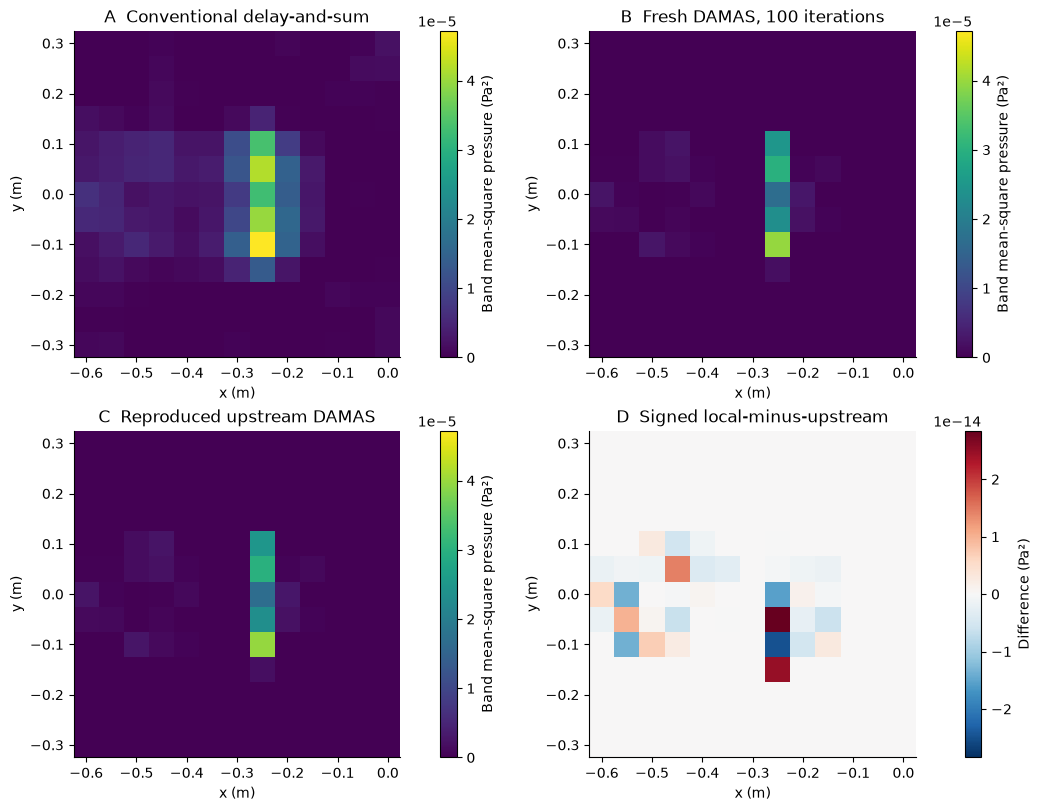

### Robustness

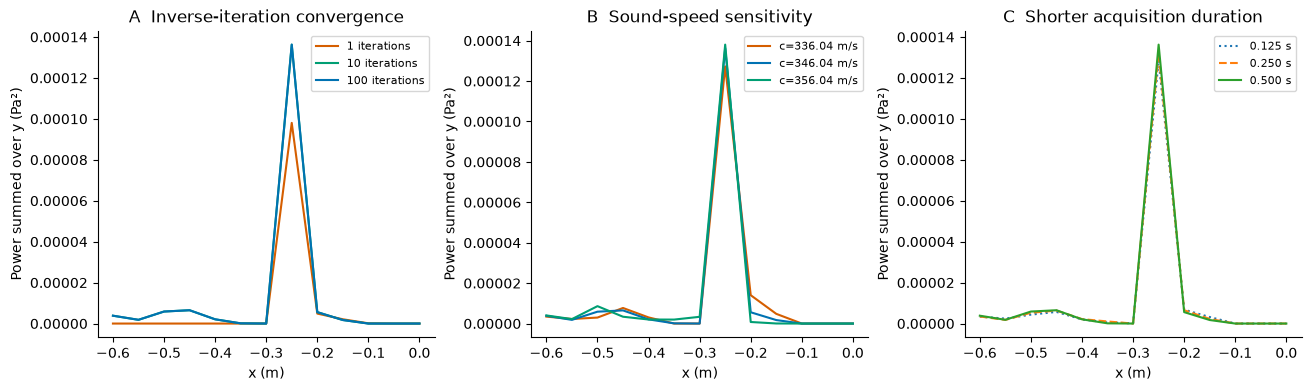

In [4]:
for figure_name,figure in figures.items():
    display(Markdown('### '+figure_name.replace('_',' ').title()))
    display(figure)
    plt.close(figure)

## Interpretation and limitations

DAMAS concentrates the array response compared with conventional delay-and-sum. The full grid, shared physical color scale, and signed difference retain sidelobes and numerical discrepancies. Iteration, propagation speed and acquisition-duration sweeps are freshly calculated. The free-field incoherent model omits flow refraction, wall reflections and coherent source interactions. The broader upstream software example is not treated as a claim that these two estimators exhaust acoustic imaging methods. The file contains 0.5 seconds despite a one-second description in the external data record.

Agreement with the standard method establishes implementation fidelity. Independent mathematical tests check operators and signs, while measured residuals and sensitivity studies bound physical interpretation. No reconstruction is relabeled as ground truth.

## Sources

Sarradj and Herold, A Python framework for microphone array data processing, Applied Acoustics 116 (2017), 50–58. https://doi.org/10.1016/j.apacoust.2016.09.015

Selected inverse method: Brooks and Humphreys, A deconvolution approach for the mapping of acoustic sources (DAMAS), Journal of Sound and Vibration 294 (2006), 856–879. https://doi.org/10.1016/j.jsv.2005.12.046. Data record: https://doi.org/10.5281/zenodo.5809069